# 🚗 QUY TRÌNH TIỀN XỬ LÝ DỮ LIỆU BIỂN SỐ XE Ô TÔ (VNLP DATASET)

Notebook này thực hiện toàn bộ quy trình tiền xử lý và chuẩn hóa dữ liệu phát hiện biển số xe ô tô từ thư mục giải nén `C:\Users\lenovo\Downloads\VNLP_detection` sang thư mục dự án `C:\Users\lenovo\licenseplate-detection\data\VNLP_detection`.

### Các bước xử lý chính:
1. **Loại bỏ xe máy:** Chỉ xử lý 2 thư mục `one_row` (biển dài) và `two_rows` (biển vuông), loại bỏ hoàn toàn `two_rows_label_xe_may`.
2. **Làm sạch nhãn biển số:** Chuẩn hóa chuỗi biển số và làm sạch các tiền tố typo (`BC`, `BD`, `B`).
3. **Chống rò rỉ dữ liệu (Anti-Data Leakage):** Gom nhóm toàn bộ ảnh đầu xe và đuôi xe của cùng một chiếc xe theo `Plate ID`. Chia tập Train (80%) / Val (10%) / Test (10%) theo danh sách **Chiếc Xe**.
4. **Chuẩn hóa nhãn sang format YOLO:** Đọc kích thước thực tế (W, H) của từng ảnh, chuyển đổi tọa độ (X1, Y1, X2, Y2) sang (x_center, y_center, width, height) chuẩn hóa [0, 1] và sinh các file `.txt` tương ứng.
5. **Tự động sinh file cấu hình `data.yaml`** sẵn sàng để huấn luyện mô hình YOLO.

In [3]:
# 1. KHAI BÁO THƯ VIỆN VÀ TỰ ĐỘNG NHẬN DIỆN ĐƯỜNG DẪN DỰ ÁN
import os
import re
import time
import random
import shutil
from pathlib import Path
from collections import defaultdict
from concurrent.futures import ThreadPoolExecutor
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt

# Tự động lấy thư mục gốc của project (nơi chứa file notebook này)
PROJECT_ROOT = Path.cwd()

# 1. Thư mục đích lưu dữ liệu chuẩn hóa (nằm ngay trong project, độc lập mọi máy tính)
DST_ROOT = PROJECT_ROOT / "data" / "VNLP_detection"

# 2. Tự động tìm thư mục dữ liệu nguồn (hỗ trợ cả trong data/raw/ hoặc thư mục Downloads của người dùng)
candidate_paths = [
    PROJECT_ROOT / "data" / "raw" / "detection",
    PROJECT_ROOT / "data" / "raw" / "VNLP_detection" / "detection",
    Path.home() / "Downloads" / "VNLP_detection" / "detection",
    Path.home() / "Downloads" / "detection"
]

SRC_ROOT = None
for p in candidate_paths:
    if p.exists() and (p / "one_row").exists():
        SRC_ROOT = p
        break

if SRC_ROOT is None:
    raise FileNotFoundError("Không tìm thấy thư mục ảnh gốc. Hãy copy folder detection vào data/raw/ hoặc thư mục Downloads!")

print(f"Thư mục dự án  : {PROJECT_ROOT}")
print(f"Thư mục nguồn  : {SRC_ROOT} (Tự động nhận diện OK)")
print(f"Thư mục đích   : {DST_ROOT} (Độc lập mọi máy tính)")


Thư mục dự án  : c:\Users\lenovo\licenseplate-detection
Thư mục nguồn  : C:\Users\lenovo\Downloads\VNLP_detection\detection (Tự động nhận diện OK)
Thư mục đích   : c:\Users\lenovo\licenseplate-detection\data\VNLP_detection (Độc lập mọi máy tính)


## 2. Quét danh sách ảnh ô tô và Làm sạch mã biển số (Plate ID)
* Chỉ lấy ảnh từ `one_row` và `two_rows`.
* Bỏ qua thư mục xe máy.

In [4]:
def clean_plate_id(plate_raw: str) -> str:
    """Chuẩn hóa chuỗi biển số và cắt bỏ tiền tố gõ nhầm (BC, BD, B)."""
    plate = plate_raw.upper()
    m = re.match(r"^(BC|BD|B)(\d{2}[A-Z].*)", plate)
    if m:
        return m.group(2)
    return plate

# Regex chuẩn cho tên file: [CamID]_[Index]_[RowType]_[PlateText]_[X1]_[Y1]_[X2]_[Y2].jpg
FILENAME_PATTERN = re.compile(r"^(\d+)_(\d+)_(\d+)_([A-Za-z0-9]+)_(\d+)_(\d+)_(\d+)_(\d+)\.jpg$")

car_files = []
for folder in ["one_row", "two_rows"]:
    folder_path = SRC_ROOT / folder
    if folder_path.exists():
        with os.scandir(folder_path) as it:
            for entry in it:
                if entry.name.endswith(".jpg"):
                    car_files.append((folder, entry.name, entry.path))

print(f"Tổng số ảnh ô tô quét được: {len(car_files)} ảnh")


Tổng số ảnh ô tô quét được: 31704 ảnh


## 3. Gom nhóm theo Xe (Group by Car) & Phân chia Train / Val / Test
* Gom tất cả ảnh đầu xe và đuôi xe của cùng một xe vào chung một nhóm.
* Chia nhóm xe theo tỷ lệ **80% Train : 10% Val : 10% Test**.

In [5]:
# Gom nhóm các ảnh thuộc cùng 1 xe
plate_groups = defaultdict(list)
for folder, name, path in car_files:
    m = FILENAME_PATTERN.match(name)
    if m:
        cam_id, idx, row_type, plate_raw, x1, y1, x2, y2 = m.groups()
        c_plate = clean_plate_id(plate_raw)
        plate_groups[c_plate].append({
            "name": name,
            "path": path,
            "coords": (int(x1), int(y1), int(x2), int(y2)),
            "folder": folder
        })

unique_cars = list(plate_groups.keys())
print(f"Tổng số chiếc xe duy nhất: {len(unique_cars)} xe")

# Phân chia ngẫu nhiên trên danh sách XE
random.seed(42)  # Cố định seed
random.shuffle(unique_cars)

n_total = len(unique_cars)
n_train = int(n_total * 0.8)
n_val = int(n_total * 0.1)

plate_to_split = {}
for p in unique_cars[:n_train]:
    plate_to_split[p] = "train"
for p in unique_cars[n_train:n_train + n_val]:
    plate_to_split[p] = "val"
for p in unique_cars[n_train + n_val:]:
    plate_to_split[p] = "test"

print(f"Phân bổ xe: {n_train} xe Train | {n_val} xe Val | {n_total - n_train - n_val} xe Test")


Tổng số chiếc xe duy nhất: 17708 xe
Phân bổ xe: 14166 xe Train | 1770 xe Val | 1772 xe Test


## 4. Thực thi Đa luồng: Copy Ảnh + Sinh Nhãn YOLO + Tạo data.yaml

In [6]:
# Tạo cấu trúc thư mục đích
for split in ["train", "val", "test"]:
    (DST_ROOT / "images" / split).mkdir(parents=True, exist_ok=True)
    (DST_ROOT / "labels" / split).mkdir(parents=True, exist_ok=True)

# Chuẩn bị danh sách tác vụ
tasks = []
for plate, items in plate_groups.items():
    split = plate_to_split[plate]
    for it in items:
        tasks.append((it, split))

def process_task(task):
    it, split = task
    src_path = it["path"]
    name = it["name"]
    x1, y1, x2, y2 = it["coords"]
    
    dst_img = DST_ROOT / "images" / split / name
    dst_lbl = DST_ROOT / "labels" / split / (Path(name).stem + ".txt")
    
    # 1. Copy ảnh (chỉ copy nếu chưa có để tiết kiệm thời gian)
    if not dst_img.exists():
        shutil.copy2(src_path, dst_img)
        
    # 2. Đọc kích thước ảnh thực tế
    with Image.open(src_path) as im:
        W, H = im.size
        
    # 3. Tính toán tọa độ chuẩn hóa YOLO [0, 1]
    xc = ((x1 + x2) / 2.0) / float(W)
    yc = ((y1 + y2) / 2.0) / float(H)
    bw = (x2 - x1) / float(W)
    bh = (y2 - y1) / float(H)
    
    # 4. Ghi file nhãn .txt
    with open(dst_lbl, "w", encoding="utf-8") as f:
        f.write(f"0 {xc:.6f} {yc:.6f} {bw:.6f} {bh:.6f}\n")

print(f"Bắt đầu xử lý {len(tasks)} ảnh và nhãn bằng đa luồng...")
t0 = time.time()
with ThreadPoolExecutor(max_workers=16) as executor:
    list(executor.map(process_task, tasks))
print(f"Xử lý hoàn tất trong {time.time() - t0:.2f} giây!")

# Tạo file data.yaml
yaml_content = f"""path: .
train: images/train
val: images/val
test: images/test

names:
  0: license_plate
"""
yaml_file = DST_ROOT / "data.yaml"
with open(yaml_file, "w", encoding="utf-8") as f:
    f.write(yaml_content)
print(f"Đã tạo file cấu hình: {yaml_file}")


Bắt đầu xử lý 31704 ảnh và nhãn bằng đa luồng...
Xử lý hoàn tất trong 21.86 giây!
Đã tạo file cấu hình: c:\Users\lenovo\licenseplate-detection\data\VNLP_detection\data.yaml


## 5. Kiểm tra Tính Toàn Vẹn & Kiểm Tra Data Leakage

In [7]:
print("=== BẢNG THỐNG KÊ DATASET SAU KHI XỬ LÝ ===")
split_plates = {}
for split in ["train", "val", "test"]:
    img_dir = DST_ROOT / "images" / split
    lbl_dir = DST_ROOT / "labels" / split
    
    imgs = os.listdir(img_dir)
    lbls = os.listdir(lbl_dir)
    
    # Lấy danh sách biển số
    plates = set(clean_plate_id(FILENAME_PATTERN.match(f).group(4)) for f in imgs if FILENAME_PATTERN.match(f))
    split_plates[split] = plates
    
    print(f"  • Tập {split.upper():5s}: {len(imgs):5d} ảnh | {len(lbls):5d} nhãn | {len(plates):5d} xe duy nhất | Khớp ảnh/nhãn: {len(imgs) == len(lbls)}")

print("\n=== KIỂM TRA RÒ RỈ DỮ LIỆU (DATA LEAKAGE) ===")
leak_train_val = len(split_plates["train"].intersection(split_plates["val"]))
leak_train_test = len(split_plates["train"].intersection(split_plates["test"]))
leak_val_test = len(split_plates["val"].intersection(split_plates["test"]))

print(f"  • Trùng lặp Train - Val  : {leak_train_val} xe (Chuẩn: 0)")
print(f"  • Trùng lặp Train - Test : {leak_train_test} xe (Chuẩn: 0)")
print(f"  • Trùng lặp Val - Test   : {leak_val_test} xe (Chuẩn: 0)")
if leak_train_val == 0 and leak_train_test == 0 and leak_val_test == 0:
    print("\n🎉 TUYỆT VỜI: 100% Không có rò rỉ dữ liệu giữa các tập!")


=== BẢNG THỐNG KÊ DATASET SAU KHI XỬ LÝ ===
  • Tập TRAIN: 25354 ảnh | 25354 nhãn | 14166 xe duy nhất | Khớp ảnh/nhãn: True
  • Tập VAL  :  3137 ảnh |  3137 nhãn |  1770 xe duy nhất | Khớp ảnh/nhãn: True
  • Tập TEST :  3213 ảnh |  3213 nhãn |  1772 xe duy nhất | Khớp ảnh/nhãn: True

=== KIỂM TRA RÒ RỈ DỮ LIỆU (DATA LEAKAGE) ===
  • Trùng lặp Train - Val  : 0 xe (Chuẩn: 0)
  • Trùng lặp Train - Test : 0 xe (Chuẩn: 0)
  • Trùng lặp Val - Test   : 0 xe (Chuẩn: 0)

🎉 TUYỆT VỜI: 100% Không có rò rỉ dữ liệu giữa các tập!


## 6. Trực quan hóa Bounding Box ngẫu nhiên để kiểm tra

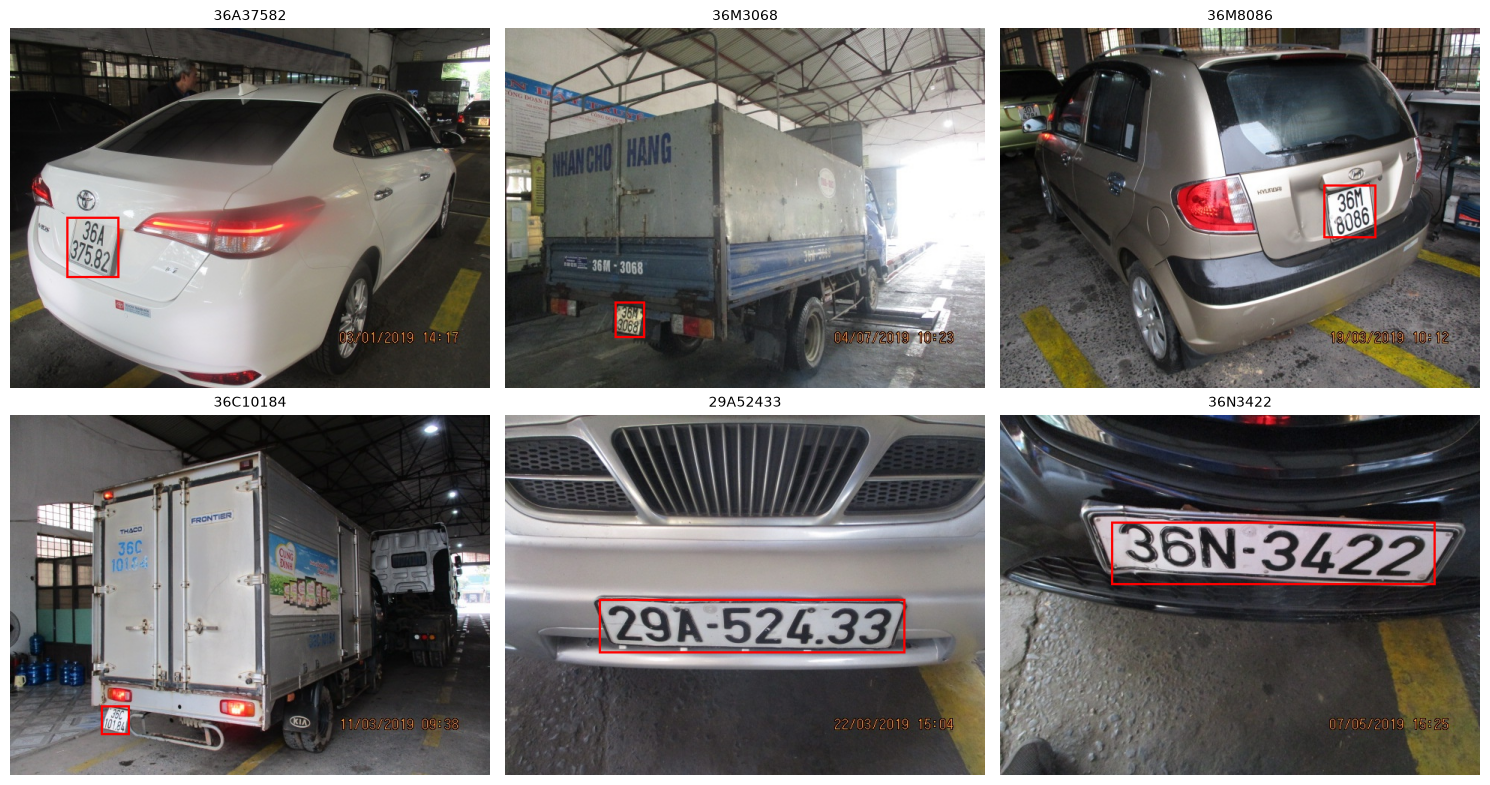

In [9]:
def visualize_samples(split="train", num_samples=6):
    img_dir = DST_ROOT / "images" / split
    lbl_dir = DST_ROOT / "labels" / split
    
    sample_files = random.sample(os.listdir(img_dir), num_samples)
    
    fig, axes = plt.subplots(2, 3, figsize=(15, 8))
    axes = axes.flatten()
    
    for idx, fn in enumerate(sample_files):
        img_path = img_dir / fn
        lbl_path = lbl_dir / (Path(fn).stem + ".txt")
        
        im = Image.open(img_path)
        W, H = im.size
        draw = ImageDraw.Draw(im)
        
        with open(lbl_path, "r") as f:
            for line in f:
                cls, xc, yc, bw, bh = map(float, line.strip().split())
                x1 = (xc - bw / 2.0) * W
                y1 = (yc - bh / 2.0) * H
                x2 = (xc + bw / 2.0) * W
                y2 = (yc + bh / 2.0) * H
                draw.rectangle([x1, y1, x2, y2], outline="red", width=3)
                
        axes[idx].imshow(im)
        axes[idx].set_title(fn.split("_")[3], fontsize=10)
        axes[idx].axis("off")
        
    plt.tight_layout()
    plt.show()

visualize_samples(split="train", num_samples=6)
